In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df=pd.read_csv("../Data/raw/PS_log.csv")

USE_POST_BALANCES = False
 
feat = pd.DataFrame(index=df.index)
feat["amount"] = df["amount"]
feat["oldbalanceOrg"] = df["oldbalanceOrg"]
feat["oldbalanceDest"] = df["oldbalanceDest"]
feat["hour"] = df["step"] % 24                                 # step = 1 hour of simulation
feat["amount_over_balance"] = df["amount"] / (df["oldbalanceOrg"] + 1)
feat["dest_old_zero"] = (df["oldbalanceDest"] == 0).astype("int8")   # known BEFORE the transaction

df["type"] = df["type"].astype("category")

for t in df["type"].cat.categories:                             # one-hot encode the type
    feat[f"type_{t}"] = (df["type"] == t).astype("int8")
    
    
if USE_POST_BALANCES:
    feat["newbalanceOrig"] = df["newbalanceOrig"]
    feat["dest_is_merchant_like"] = ((df["oldbalanceDest"] == 0) & (df["newbalanceDest"] == 0)).astype("int8")  # uses a POST balance
    feat["newbalanceDest"] = df["newbalanceDest"]
    feat["err_orig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
    feat["err_dest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
 
y = df["isFraud"]
print(feat.shape)

(6362620, 11)


In [29]:
# %% 4. Split (stratified keeps the tiny fraud share equal in both sets)
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(
    feat, y, test_size=0.25, random_state=0, stratify=y
)
print(f"Train: {len(X_tr):,} rows, {y_tr.sum():,} frauds | Test: {len(X_te):,} rows, {y_te.sum():,} frauds")
# A more realistic variant: train on early `step` values, test on later ones (no peeking at the future).

# %% 5. Baseline: logistic regression (scaled)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, confusion_matrix)
X_tr=X_tr.astype("float32")
X_te=X_te.astype("float32")

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
logit.fit(X_tr, y_tr)
p_logit = logit.predict_proba(X_te)[:, 1]
print(f"Logistic  PR-AUC: {average_precision_score(y_te, p_logit):.3f}   ROC-AUC: {roc_auc_score(y_te, p_logit):.3f}")
# PR-AUC is the headline metric for rare events. A useless model scores about the fraud rate.
print(f"(PR-AUC of a model with no skill = the fraud rate = {y_te.mean():.4f})")

 

Train: 4,771,965 rows, 6,160 frauds | Test: 1,590,655 rows, 2,053 frauds
Logistic  PR-AUC: 0.186   ROC-AUC: 0.984
(PR-AUC of a model with no skill = the fraud rate = 0.0013)


In [30]:
# %% 6. A stronger model: gradient boosting (fast on millions of rows)
from sklearn.ensemble import HistGradientBoostingClassifier
gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)
gb.fit(X_tr, y_tr)
p_gb = gb.predict_proba(X_te)[:, 1]
print(f"Boosting  PR-AUC: {average_precision_score(y_te, p_gb):.3f}   ROC-AUC: {roc_auc_score(y_te, p_gb):.3f}")

# %% 7. Pick a threshold; the 0.5 default is just a convention
def report(p, name):
    print(f"\n{name}\nthreshold  precision  recall  flagged  missed_frauds  false_alarms")
    for t in [0.9, 0.7, 0.5, 0.3, 0.1, 0.05]:
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
        print(f"  {t:.2f}      {precision_score(y_te, pred, zero_division=0):.3f}     "
              f"{recall_score(y_te, pred):.3f}   {pred.sum():>7,}   {fn:>8,}   {fp:>10,}")

report(p_logit, "Logistic (class_weight='balanced')")
report(p_gb, "Gradient boosting")

Boosting  PR-AUC: 0.805   ROC-AUC: 0.939

Logistic (class_weight='balanced')
threshold  precision  recall  flagged  missed_frauds  false_alarms
  0.90      0.059     0.722    25,168        571       23,686
  0.70      0.032     0.865    55,817        278       54,042
  0.50      0.018     0.942   107,059        119      105,125
  0.30      0.010     0.985   203,701         30      201,678
  0.10      0.005     0.999   403,306          3      401,256
  0.05      0.004     0.999   474,382          3      472,332

Gradient boosting
threshold  precision  recall  flagged  missed_frauds  false_alarms
  0.90      0.822     0.821     2,050        367          364
  0.70      0.824     0.832     2,074        345          366
  0.50      0.700     0.848     2,485        313          745
  0.30      0.582     0.885     3,123        236        1,306
  0.10      0.493     0.933     3,888        138        1,973
  0.05      0.492     0.934     3,897        135        1,979


In [31]:
# # %% 6. A stronger model: gradient boosting (fast on millions of rows)
# from sklearn.ensemble import HistGradientBoostingClassifier
# gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)
# gb.fit(X_tr, y_tr)
# p_gb = gb.predict_proba(X_te)[:, 1]
# print(f"Boosting  PR-AUC: {average_precision_score(y_te, p_gb):.3f}   ROC-AUC: {roc_auc_score(y_te, p_gb):.3f}")



In [32]:
# %% 7. Pick a threshold; the 0.5 default is just a convention
def report(p, name):
    print(f"\n{name}\nthreshold  precision  recall  flagged  missed_frauds  false_alarms")
    for t in [0.9, 0.7, 0.5, 0.3, 0.1, 0.05]:
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
        print(f"  {t:.2f}      {precision_score(y_te, pred, zero_division=0):.3f}     "
              f"{recall_score(y_te, pred):.3f}   {pred.sum():>7,}   {fn:>8,}   {fp:>10,}")

report(p_logit, "Logistic (class_weight='balanced')")
report(p_gb, "Gradient boosting")
# Note how 'balanced' logistic probabilities are inflated, so its good thresholds sit differently.




Logistic (class_weight='balanced')
threshold  precision  recall  flagged  missed_frauds  false_alarms


  0.90      0.059     0.722    25,168        571       23,686
  0.70      0.032     0.865    55,817        278       54,042
  0.50      0.018     0.942   107,059        119      105,125
  0.30      0.010     0.985   203,701         30      201,678
  0.10      0.005     0.999   403,306          3      401,256
  0.05      0.004     0.999   474,382          3      472,332

Gradient boosting
threshold  precision  recall  flagged  missed_frauds  false_alarms
  0.90      0.822     0.821     2,050        367          364
  0.70      0.824     0.832     2,074        345          366
  0.50      0.700     0.848     2,485        313          745
  0.30      0.582     0.885     3,123        236        1,306
  0.10      0.493     0.933     3,888        138        1,973
  0.05      0.492     0.934     3,897        135        1,979


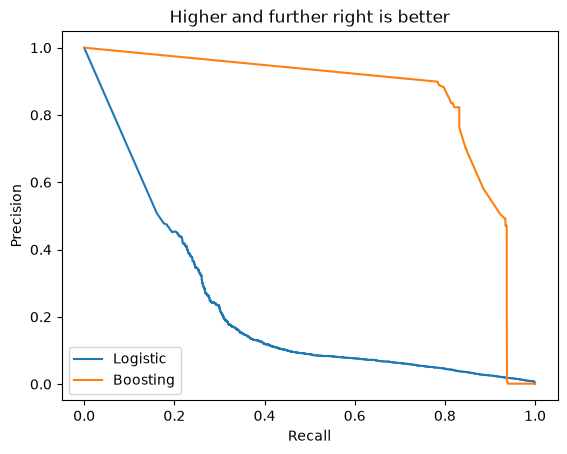

In [33]:
# %% 8. Precision-recall curves side by side
from sklearn.metrics import precision_recall_curve
for p, name in [(p_logit, "Logistic"), (p_gb, "Boosting")]:
    pr, rc, _ = precision_recall_curve(y_te, p)
    plt.plot(rc, pr, label=name)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend()
plt.title("Higher and further right is better"); plt.show()

In [34]:
# %% 9. What does the model rely on? (permutation importance on a sample, so it stays fast)
from sklearn.inspection import permutation_importance
idx = np.random.default_rng(0).choice(len(X_te), size=min(200_000, len(X_te)), replace=False)
Xs, ys = X_te.iloc[idx], y_te.iloc[idx]
imp = permutation_importance(gb, Xs, ys, scoring="average_precision", n_repeats=3, random_state=0)
print(pd.Series(imp.importances_mean, index=Xs.columns).sort_values(ascending=False).round(4))
# If one feature dominates (e.g. err_orig), re-run with USE_POST_BALANCES = False and compare.


amount_over_balance    0.8285
amount                 0.5402
type_TRANSFER          0.3988
oldbalanceDest         0.2819
oldbalanceOrg          0.2770
type_CASH_OUT          0.2148
hour                   0.0519
dest_old_zero          0.0232
type_CASH_IN           0.0024
type_DEBIT             0.0000
type_PAYMENT           0.0000
dtype: float64


In [35]:
p_gb_series = pd.Series(p_gb, index=y_te.index)
blind = X_te[(y_te == 1) & (p_gb_series < 0.05)]
caught = X_te[(y_te == 1) & (p_gb_series >= 0.5)]

cols = ["amount", "oldbalanceOrg", "oldbalanceDest", "hour", "amount_over_balance"]
print(len(blind), "undetected frauds")
print(pd.concat([blind[cols].median(), caught[cols].median()], axis=1,
                keys=["undetected", "caught"]))
print(blind.filter(like="type_").mean())

135 undetected frauds
                        undetected         caught
amount               279728.812500  637714.937500
oldbalanceOrg        257811.921875  637714.937500
oldbalanceDest        83491.601562       0.000000
hour                     14.000000      10.000000
amount_over_balance       0.999997       0.999998
type_CASH_IN     0.00000
type_CASH_OUT    0.97037
type_DEBIT       0.00000
type_PAYMENT     0.00000
type_TRANSFER    0.02963
dtype: float32


In [36]:
profile = ((X_te["type_CASH_OUT"] == 1)
           & (X_te["amount_over_balance"] > 0.999)
           & (X_te["oldbalanceDest"] > 0))

print("rows with this profile:", profile.sum())
print("of which fraud:", y_te[profile].sum(), f"({y_te[profile].mean():.4%})")
print("blind frauds inside the profile:", (profile & (y_te == 1) & (p_gb_series < 0.05)).sum())

rows with this profile: 429674


of which fraud: 725 (0.1687%)
blind frauds inside the profile: 85


In [37]:
cut = df["step"].quantile(0.8)
tr, te = (df["step"] <= cut), (df["step"] > cut)
Xa, Xb = feat[tr].astype("float32"), feat[te].astype("float32")
ya, yb = y[tr], y[te]

gb_t = HistGradientBoostingClassifier(max_depth=6, learning_rate=0.1, max_iter=300,
                                      class_weight="balanced", random_state=0)
gb_t.fit(Xa, ya)
p_t = gb_t.predict_proba(Xb)[:, 1]

print(f"Time-split PR-AUC: {average_precision_score(yb, p_t):.3f}")
print(f"test frauds: {yb.sum():,}  rate: {yb.mean():.4f}")
for t in [0.9, 0.5, 0.3]:
    pr = (p_t >= t).astype(int)
    print(t, f"precision={precision_score(yb, pr, zero_division=0):.3f}",
             f"recall={recall_score(yb, pr):.3f}", f"flagged={pr.sum():,}")

Time-split PR-AUC: 1.000
test frauds: 4,250  rate: 0.0034
0.9 precision=0.998 recall=1.000 flagged=4,257
0.5 precision=0.988 recall=1.000 flagged=4,299
0.3 precision=0.978 recall=1.000 flagged=4,343


In [38]:
print("USE_POST_BALANCES =", USE_POST_BALANCES)
print(sorted(feat.columns))

USE_POST_BALANCES = False
['amount', 'amount_over_balance', 'dest_old_zero', 'hour', 'oldbalanceDest', 'oldbalanceOrg', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [ ]:
import joblib, json, os
for d in ["../models", "../Data/processed", "../results/metrics", "../results/figures"]:
    os.makedirs(d, exist_ok=True)

joblib.dump(gb, "../models/gbm_fraud.joblib")
joblib.dump(logit, "../models/logit_baseline.joblib")
json.dump({"features": list(X_tr.columns), "threshold": 0.90,
           "use_post_balances": bool(USE_POST_BALANCES),
           "split": "random stratified 75/25, random_state=0"},
          open("../models/model_meta.json", "w"), indent=2)
X_te.assign(isFraud=y_te.values).to_csv("../Data/processed/test_set.csv", index=False)